# PostgreSQL Transactions and Lock Diagnosis

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lolusername/CST4714_DB_admin/blob/main/week_05/materials/notebooks/02_postgres_transactions_locks.ipynb)

[View on GitHub](https://github.com/lolusername/CST4714_DB_admin/blob/main/week_05/materials/notebooks/02_postgres_transactions_locks.ipynb)

**Lab 2 is the assignment. This notebook is the file you run in Colab.**
Colab runs the supplied Python cells, and Supabase hosts the PostgreSQL database
those cells connect to. Complete the comparison and explanation in this notebook.

Supabase's SQL editor already connects inside your project. Colab runs outside
that project, so it needs a PostgreSQL connection URL before it can send SQL.
Today's notebook creates its own `lock_lab` table. It does not need yesterday's
event IDs or another copy of the Metro Support setup.

**Language and environment:** Python 3 uses Psycopg to send SQL to PostgreSQL.
Run in Colab or local Jupyter. A course PostgreSQL connection is needed for the
live exercise; the labeled offline transcript is for interpretation only.

This notebook creates one controlled blocking relationship in a disposable schema,
identifies the blocked and blocking sessions, resolves the blocker, and verifies
the final row.

**The central idea:** a wait is a relationship between database sessions. Diagnose
that relationship before terminating or changing anything.

The cloud path asks for a temporary PostgreSQL URL with `getpass`, so the value is
not displayed or written into the notebook. A labeled transcript supports
interpretation when a connection is unavailable; it does not execute PostgreSQL.

## Run order and submission

Run numbered cells in order and stop at each student workspace. The cell title is the number used in the teaching guide. Collapsed setup still runs; expand it to inspect the implementation.

| Cell | What you do |
|---|---|
| 01 | Install the PostgreSQL driver (body collapsed) |
| 02 | Choose live mode and the ending of A |
| 03 | Connect the three named sessions (body collapsed) |
| 04 | Create the disposable one-row fixture (body collapsed) |
| 05 | Read Session A’s UPDATE |
| 06 | Read Session B’s UPDATE and the diagnostic query |
| 07 | Run and safely finish the blocking experiment (body collapsed) |
| 08 | Inspect the captured waiting-writer evidence |
| 09 | Compare the final row |
| 10 | Clean up the lab schema and close all sessions (body collapsed) |

Submit the viewable sharing link to your saved Colab copy in Brightspace, including your SQL, outputs, and explanations. Give the instructor viewer access.


## Data reference before the first query

**This notebook uses one simplified row:** `lock_lab.tickets(ticket_id integer primary key, priority text not null, status text not null)` begins with `(1004, medium, open)`. A changes priority to high; B changes status to in_progress. The actual SQL stays visible. `USE_CLOUD = False` selects the supplied transcript for interpretation. Switch it to True only after preparing your personal course connection.

### Complete Metro Support fixture

Metro Support is a fictional help desk. All people and records are synthetic.
The complete lab fixture contains **8 users, 12 tickets, and 21 events**. A user
may request many tickets; a ticket may have one assignee or no assignee; a ticket
may have many history events. Requester, assignee, and actor refer to different
roles and all point to `users.user_id`.

The fixture contains the values shown here. The
baseline SQL declares keys, required fields, unique email, and the date-order
check. In the integrity lab, you add CHECK constraints for some of the allowed values in status, priority, category, and role.

Every row has the declared columns. SQL NULL is a value marker for missing or
inapplicable information. Empty
CSV fields in this fixture load as SQL NULL. The SQL uses explicit integer IDs;
the identity experiment later creates a separate generated `note_id`.

### users

One row represents one person.

| Field | Type and rule | Meaning |
|---|---|---|
| `user_id` | integer; primary key | Unique person identifier; supplied explicitly in this fixture |
| `display_name` | text; required | Synthetic display label; join on the user ID |
| `email` | text; required and unique | Synthetic contact address ending in example.test |
| `role` | text; required | Observed: resident, agent, supervisor, analyst |
| `neighborhood` | text; required | Observed: Harbor, Northside, Central |
| `created_at` | timestamp with time zone; required | When the user record was created |

One complete example record (JSON notation for readability; SQL uses typed columns):

```json
{
  "user_id": 101,
  "display_name": "Requester 101",
  "email": "requester101@example.test",
  "role": "resident",
  "neighborhood": "Harbor",
  "created_at": "2026-01-08T14:20:00Z"
}
```

### tickets

One row represents one request.

| Field | Type and rule | Meaning |
|---|---|---|
| `ticket_id` | integer; primary key | One stable identifier for one request |
| `requester_id` | integer; required foreign key | Person who reported the request; references users.user_id |
| `assignee_id` | integer; nullable foreign key | Staff member assigned to the request; NULL means unassigned |
| `category` | text; required | Observed: parks, sanitation, streetlight, transportation, water |
| `priority` | text; required | Observed: low, medium, high, urgent |
| `status` | text; required | Observed: new, open, in_progress, resolved, closed |
| `subject` | text; required | Short description of the request |
| `opened_at` | timestamp with time zone; required | When the request was recorded |
| `closed_at` | timestamp with time zone; nullable | Closure time when recorded |

One complete example record (JSON notation for readability; SQL uses typed columns):

```json
{
  "ticket_id": 1001,
  "requester_id": 101,
  "assignee_id": 201,
  "category": "streetlight",
  "priority": "high",
  "status": "open",
  "subject": "Streetlight dark near bus stop",
  "opened_at": "2026-02-01T23:10:00Z",
  "closed_at": null
}
```

### ticket_events

One row represents one event on one request.

| Field | Type and rule | Meaning |
|---|---|---|
| `event_id` | integer; primary key | One stable identifier for one history event |
| `ticket_id` | integer; required foreign key | Request this event describes; references tickets.ticket_id |
| `actor_id` | integer; required foreign key | Person who acted; references users.user_id |
| `event_type` | text; required | Observed: created, assigned, status_changed |
| `old_status` | text; nullable | Prior status when relevant; absent for a creation event |
| `new_status` | text; nullable | Recorded resulting status when relevant |
| `note` | text; nullable | Explanation attached to the event |
| `event_at` | timestamp with time zone; required | When the event was recorded |

One complete example record (JSON notation for readability; SQL uses typed columns):

```json
{
  "event_id": 5001,
  "ticket_id": 1001,
  "actor_id": 101,
  "event_type": "created",
  "old_status": null,
  "new_status": "open",
  "note": "Reported through mobile form",
  "event_at": "2026-02-01T23:10:00Z"
}
```

### Names that change between exercises

- Week 1 uses a four-ticket extract and a two-row `agents` table. Its `agent_id`
  corresponds to the later `users.user_id`; its `name` corresponds to `display_name`.
- The first Week 2 examples use a smaller **4 / 6 / 9** fixture in `main`, with
  fewer columns. The separate **8 / 12 / 21** lab fixture uses `metro_support`.
  They are different instances; do not transfer requester IDs or counts between them.
- Week 5's `lock_lab.tickets` intentionally has only `ticket_id`, `priority`,
  and `status`. Its complete starting row is **1004 / medium / open**. The main
  Metro Support row 1004 is **low / new**. Always name the schema when explaining it.
- In the full fixture, active means `new`, `open`, or `in_progress`. Week 1's
  smaller question defines active as only `new` or `open`.

The original CSV files retain every record. The notebook also provides a named
fixture-loading cell and a visible count check before the lab queries.


## Worked still diagram

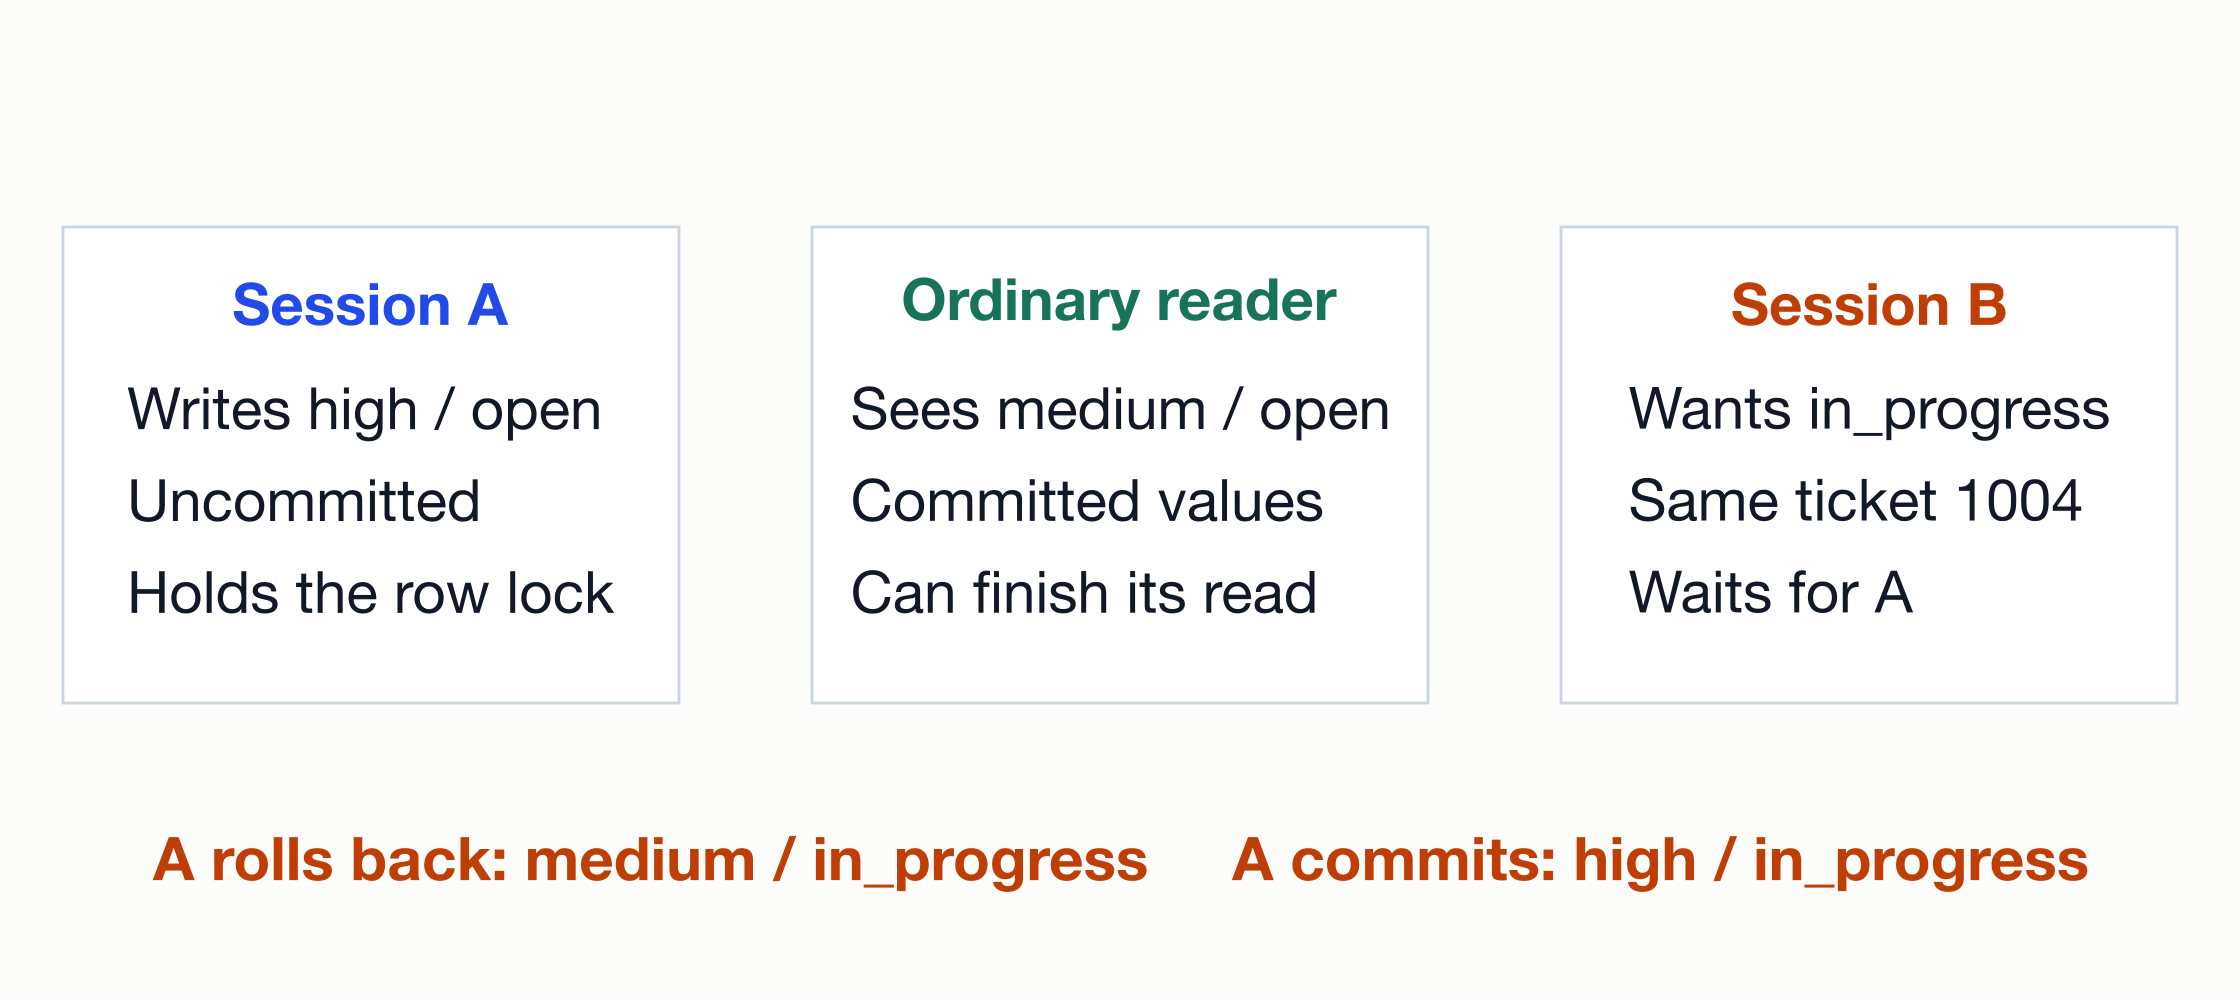

Session A changes ticket 1004 to high/open without committing and holds its row lock. An ordinary reader sees committed medium/open. Session B waits to set in_progress. A rollback leaves medium/in_progress; A commit leaves high/in_progress.


## First-Time Setup: Colab and Supabase

Use your existing personal course project in Supabase. Run the notebook cells
in Colab. Keep the Supabase tab open to get the connection details.

1. **Colab:** choose **File > Save a copy in Drive** and work in that copy.
2. **Supabase:** open your course project, click **Connect**, choose
   **Session pooler**, and copy the **PostgreSQL URI**. It begins with
   `postgresql://`. Keep the actual host, username, and port from that string.
   The project HTTPS URL and API keys are not PostgreSQL connection strings.
3. Replace `[YOUR-PASSWORD]` with the **database password for that project**.
   Your Supabase website login password is a different credential. Reserved
   characters in the password need URL encoding: `@` becomes `%40`, `#`
   becomes `%23`, and `%` becomes `%25`. Encode only the password, once.
4. Add the encrypted-connection setting. If the URL ends in `/postgres`,
   change that ending to `/postgres?sslmode=require`. If other query
   parameters already follow a `?`, append `&sslmode=require` instead.
   If `sslmode` is already present, change its existing value to `require`
   or keep `verify-ca` or `verify-full`; do not add it twice.
5. **Back in Colab:** find the configuration cell below. Set
   `USE_CLOUD = True` and leave `KEEP_A_CHANGE = False` for the first run.
6. Click the play button beside each code cell, starting at the top. Run
   the install cell, the configuration cell, then the connection cell in
   **Section 1**. When it asks **Paste the temporary PostgreSQL connection URL:**,
   paste your prepared URL into that hidden input and press Enter. Never put
   a password-bearing URL into a code cell, Markdown cell, or shared chat.
7. Continue only after you see **Opened Session A, Session B, and the
   diagnostic session.** Run **Section 2** and check that it prints
   `Starting row: (1004, 'medium', 'open')`. These are two separate checkpoints.

### If You Cannot Reach the Starting Row

| What you see | What to check before continuing |
|---|---|
| Cloud path skipped | Set `USE_CLOUD = True` and rerun the configuration cell, then Section 1. |
| A cell waits at the hidden prompt | Paste the URL into the input and press Enter. |
| Add sslmode=require or a stronger mode | Correct the URL's SSL setting, then rerun Section 1. |
| URL could not be parsed or connection failed | Check the project is running, copy a fresh Session pooler URI, and check the database password and its URL encoding. Stop before Section 2. |

If access remains unavailable, tell the instructor and use the **Offline
Fallback Incident Transcript** below. Label its result as a supplied trace
and the commit result as an unexecuted prediction.

**Why Session pooler:** this exercise needs three persistent connections.
Session mode supports IPv4 and retains each connection's database session.
Use the method shown in Connect; do not substitute Transaction pooler.

**Why SSL:** `require` encrypts the classroom connection but does not verify
the server hostname. A production setup uses `verify-full` with the Supabase
CA certificate. The notebook also accepts `verify-ca` and `verify-full`.

The public notebook defaults to `USE_CLOUD = False`. Its fallback can run
without credentials, but that does not establish a live database connection.

[Supabase connection methods](https://supabase.com/docs/guides/database/connecting-to-postgres)

In [ ]:
#@title Cell 01 · Install the PostgreSQL driver
%pip -q install "psycopg[binary]"

In [ ]:
#@title Cell 02 · Choose live mode and the ending of A
from getpass import getpass
import threading
import time

import psycopg
from psycopg.conninfo import conninfo_to_dict

USE_CLOUD = False  # Change to True during the in-class cloud lab.
KEEP_A_CHANGE = False  # First run: rollback A. Second run: set True to commit A.
print("Cloud path enabled:", USE_CLOUD)

## 1. Open Three Clearly Named Sessions

- **Session A** will update a row and deliberately remain uncommitted.
- **Session B** will attempt a competing update and wait.
- **Diagnostic session** will query PostgreSQL's activity and lock state.

Three connections make the roles visible. The diagnostic session does not cause
or resolve the block; it observes it.

**Before reading the output: PID means process identifier.** PostgreSQL uses a
server process (backend) to serve each persistent session in this experiment.
`pg_backend_pid()` asks PostgreSQL for that process's number. It identifies the backend process handling the database connection.
The three sessions can share one database account while having different PIDs.
A persistent session can keep its PID across queries and commits; reconnecting
may change it. Use the actual values captured by this run.

When B's PID is 7332 and `pg_blocking_pids(7332)` returns `[7310]`, B is waiting
for A, whose PID is 7310. PostgreSQL may show the same array as `{7310}`.
An empty list on A means A is not waiting on a reported blocker; it does not
mean A cannot block B. These numbers illustrate the supplied trace.

Run the cell below and enter the URL at its hidden prompt. Expect
**Opened Session A, Session B, and the diagnostic session.** before moving
to Section 2. A connection error must be resolved before running later cells.

In [ ]:
#@title Cell 03 · Connect the three named sessions
if USE_CLOUD:
    database_url = getpass("Paste the temporary PostgreSQL connection URL: ")

    try:
        sslmode = conninfo_to_dict(database_url).get("sslmode", "prefer")
    except psycopg.Error:
        database_url = None
        raise ValueError("The connection URL could not be parsed. Copy a fresh Session pooler URL.") from None
    if sslmode not in {"require", "verify-ca", "verify-full"}:
        database_url = None
        raise ValueError("Add sslmode=require or a stronger mode to the temporary URL.")

    session_a = session_b = diagnostic = None
    try:
        session_a = psycopg.connect(
            database_url, application_name="cst4714_session_a", connect_timeout=10
        )
        session_b = psycopg.connect(
            database_url, application_name="cst4714_session_b", connect_timeout=10
        )
        diagnostic = psycopg.connect(
            database_url, application_name="cst4714_diagnostic", connect_timeout=10
        )
        diagnostic.autocommit = True
    except psycopg.Error:
        for connection in (session_a, session_b, diagnostic):
            if connection is not None:
                connection.close()
        raise RuntimeError("Connection failed. Check project status, Session pooler URL, password, and SSL mode.") from None
    finally:
        database_url = None

    print("Opened Session A, Session B, and the diagnostic session.")
else:
    print("Cloud path skipped. Continue to the fallback transcript below.")

## 2. Create a Disposable Target

The table has one row. Its original state is `priority = medium` and
`status = open`. This deliberately simplified fixture differs from the full
Metro Support ticket. Recreating `lock_lab` resets only this exercise.

In [ ]:
#@title Cell 04 · Create the disposable one-row fixture
if USE_CLOUD:
    with diagnostic.cursor() as cursor:
        cursor.execute("DROP SCHEMA IF EXISTS lock_lab CASCADE")
        cursor.execute("CREATE SCHEMA lock_lab")
        cursor.execute("""
            CREATE TABLE lock_lab.tickets (
                ticket_id integer PRIMARY KEY,
                priority text NOT NULL,
                status text NOT NULL
            )
        """)
        cursor.execute("""
            INSERT INTO lock_lab.tickets (ticket_id, priority, status)
            VALUES (1004, 'medium', 'open')
        """)
        cursor.execute("SELECT * FROM lock_lab.tickets")
        print("Starting row:", cursor.fetchone())
else:
    print("Setup skipped because USE_CLOUD is False.")

## 3. Session A Holds an Uncommitted Row Change

Session A will change the priority without committing. Read this statement and
predict what a second writer will do. The next experiment runs both sessions,
captures the waiting relationship, and releases the lock in the same cell. You
can study its saved results without leaving a database transaction open.

For the first run, `KEEP_A_CHANGE = False` discards A's proposed priority change.
After cleanup, change it to `True` and run again from the configuration cell.
Predict the second final row before running it. B's SQL stays the same.

In [ ]:
#@title Cell 05 · Read Session A’s UPDATE
session_a_sql = """
    UPDATE lock_lab.tickets
    SET priority = 'high'
    WHERE ticket_id = 1004
    RETURNING ticket_id, priority, status
"""
print("Session A will run this UPDATE without committing:")
print(session_a_sql)

## 4. Session B Starts a Competing Update

The notebook uses one small background thread because a blocked query cannot both
wait and let the same notebook cell collect diagnostics. The experiment captures
the real PostgreSQL lock relationship, ends A's transaction, and lets B commit
before the cell ends. `KEEP_A_CHANGE` chooses A's outcome. The `finally` block
rolls back any remaining transaction if the experiment fails.

Run the supplied threading code. Follow the SQL and the
transaction decisions. The small worker below allows B to wait while another
connection runs the diagnostic query.

### Visible SQL for the waiting writer and diagnosis

Read these filters before running the controlled experiment. The collapsed runner below starts the thread, captures the wait, releases A, and saves the results. Its printed results remain visible.


In [ ]:
#@title Cell 06 · Read Session B’s UPDATE and the diagnostic query
session_b_sql = '''
UPDATE lock_lab.tickets
SET status = 'in_progress'
WHERE ticket_id = 1004
RETURNING ticket_id, priority, status
'''
diagnostic_sql = '''
SELECT pid, application_name, state, wait_event_type, wait_event,
       pg_blocking_pids(pid) AS blocking_pids,
       xact_start, clock_timestamp() - xact_start AS transaction_age,
       left(query, 90) AS query_sample
FROM pg_stat_activity
WHERE pid IN (%s, %s)
ORDER BY application_name
'''
print('B changes only ticket 1004. The diagnostic query observes A and B.')


### Run the bounded experiment

This cell can wait briefly. It always releases A and checks that B finishes. It does not leave a lab row lock held while you read the next sections.


In [ ]:
#@title Cell 07 · Run and safely finish the blocking experiment
blocked_result = {}

def run_session_b_update():
    try:
        with session_b.cursor() as cursor:
            cursor.execute("SET statement_timeout = '15s'")
            cursor.execute(session_b_sql)
            blocked_result["row"] = cursor.fetchone()
        session_b.commit()
        blocked_result["outcome"] = "committed after blocker released"
    except Exception as error:
        session_b.rollback()
        blocked_result["outcome"] = f"error: {type(error).__name__}"


rows = []
columns = []
session_b_thread = None

if USE_CLOUD:
    try:
        with session_a.cursor() as cursor:
            cursor.execute("SET idle_in_transaction_session_timeout = '30s'")
            cursor.execute("SELECT pg_backend_pid()")
            a_pid = cursor.fetchone()[0]
            cursor.execute(session_a_sql)
            session_a_row = cursor.fetchone()
        # Psycopg began a transaction. A has not committed.
        with diagnostic.cursor() as cursor:
            cursor.execute("SELECT ticket_id, priority, status FROM lock_lab.tickets")
            reader_row = cursor.fetchone()
        with session_b.cursor() as cursor:
            cursor.execute("SELECT pg_backend_pid()")
            b_pid = cursor.fetchone()[0]
        # Ask PostgreSQL itself for PIDs, rather than a proxy's protocol identity.
        session_pids = (a_pid, b_pid)
        session_b_thread = threading.Thread(target=run_session_b_update)
        session_b_thread.start()

        # Capture the real wait instead of assuming it began after a fixed sleep.
        for attempt in range(100):
            with diagnostic.cursor() as cursor:
                cursor.execute(diagnostic_sql, session_pids)
                columns = [column.name for column in cursor.description]
                rows = cursor.fetchall()
            if any(row[0] == session_pids[1] and session_pids[0] in row[5] for row in rows):
                break
            time.sleep(0.05)
        else:
            raise RuntimeError("No blocking relationship was captured; rerun from setup.")
        if KEEP_A_CHANGE:
            session_a.commit()
        else:
            session_a.rollback()
    finally:
        # Always release A, even when diagnosis raises an error.
        session_a.rollback()
        if session_b_thread is not None:
            session_b_thread.join(timeout=20)
    if session_b_thread is not None and session_b_thread.is_alive():
        session_b.cancel()
        session_b_thread.join(timeout=5)
        raise RuntimeError("Session B did not finish; close the connections and rerun.")

    with diagnostic.cursor() as cursor:
        cursor.execute("SELECT ticket_id, priority, status FROM lock_lab.tickets")
        final_row = cursor.fetchone()
    assert blocked_result.get("outcome") == "committed after blocker released", blocked_result
    expected_priority = "high" if KEEP_A_CHANGE else "medium"
    assert final_row == (1004, expected_priority, "in_progress"), final_row
    print("A saw its uncommitted change:", session_a_row)
    print("An ordinary reader still saw:", reader_row)
    print("Captured a waiting writer, released A, and verified B's commit.")
    print("The next sections inspect the saved results. No lab row lock remains.")
else:
    print("Experiment skipped. Use the supplied transcript below.")

## 5. Ask PostgreSQL Who Is Blocking Whom

`pg_blocking_pids(pid)` directly reports the blocker relationship. The
wait event adds context. A PID identifies a session; it is not automatic
permission to terminate a process.

The query now selects only the two PIDs opened by this run. `%s` marks a value
supplied separately by Psycopg; it is not SQL you should replace by string
concatenation. `transaction_age` is measured at capture time. The waiter can
have `state = active` and still have `wait_event_type = Lock`.

In [ ]:
#@title Cell 08 · Inspect the captured waiting-writer evidence
if USE_CLOUD:
    print("Snapshot captured while B was waiting:")
    for row in rows:
        print(f"\nSession {row[1]} (PID {row[0]})")
        for label, value in zip(columns[2:], row[2:]):
            print(f"  {label}: {value}")
else:
    print("Read the blocked and blocking PIDs in the fallback transcript.")

## 6. Resolve the Blocker and Verify the Final State

This is where you read the final result. The experiment in Section 4 already
ended A and let B finish; Section 5 displays the wait it captured earlier.
Both runs should finish successfully. No duplicate-key error is expected.

Both choices end A's transaction and release the row lock. Rollback discards its
priority change; commit keeps it. B then commits `status = in_progress` in either
case. Read the ticket’s final status and priority.

- First run, `KEEP_A_CHANGE = False`: `(1004, 'medium', 'in_progress')`.
- Second run, `KEEP_A_CHANGE = True`: `(1004, 'high', 'in_progress')`.

Run Section 7 cleanup after each experiment. Record the first result in the
final Markdown cell before rerunning from configuration for the second case.

In [ ]:
#@title Cell 09 · Compare the final row
if USE_CLOUD:
    print("A's resolution:", "COMMIT" if KEEP_A_CHANGE else "ROLLBACK")
    print("Session B outcome:", blocked_result)
    print("Final row captured from a fresh statement:", final_row)
else:
    print("Compare A's discarded priority change with B's committed status change.")

## 7. Close Connections and Remove the Disposable Schema

Cleanup is part of the operation. It prevents an old practice lock or test table
from becoming a later mystery.

In [ ]:
#@title Cell 10 · Clean up the lab schema and close all sessions
if USE_CLOUD:
    with diagnostic.cursor() as cursor:
        cursor.execute("DROP SCHEMA IF EXISTS lock_lab CASCADE")

    session_a.close()
    session_b.close()
    diagnostic.close()
    database_url = None
    print("Closed all sessions and removed lock_lab.")
else:
    print("No cloud resources were opened.")

## Offline Fallback Incident Transcript

Use this illustrative transcript when the cloud path cannot run. The values below illustrate a rollback run. It represents the rollback
case. Predict the commit case separately; label that result as a prediction.

```text
Starting row: (1004, 'medium', 'open')

Session A PID 7310, application cst4714_session_a
Transaction began: 2026-03-05 18:42:10+00
Uncommitted query: UPDATE lock_lab.tickets SET priority = 'high'
                   WHERE ticket_id = 1004

Session B PID 7332, application cst4714_session_b
State: active
wait_event_type: Lock
wait_event: transactionid
pg_blocking_pids(7332): {7310}
Query: UPDATE lock_lab.tickets SET status = 'in_progress'
       WHERE ticket_id = 1004

Action: ROLLBACK issued in Session A.
Session B outcome: committed after blocker released.
Final row: (1004, 'medium', 'in_progress')
```

The transcript records one blocking relationship, the chosen resolution, and the
final state. It does not determine how a production application should choose
between waiting, rollback, cancellation, or termination.

## Your Comparison and Incident Update

Before the second run, keep the first final row here and predict the second.
After running again, replace the second observation with your result.

| A's decision | Predicted final priority/status | Observed final priority/status |
|---|---|---|
| ROLLBACK | Your prediction | Your result |
| COMMIT | Your prediction | Your result |

In the same cell, write a short update to the developer whose status update
appeared stuck. Use one run's PIDs and `pg_blocking_pids` result to explain the
wait, then explain why both runs let B finish but kept different priority values.
What would you check before making the same decision on a live application?

If you used the transcript, label the first row **supplied trace** and the second
**unexecuted prediction**.

Before submitting, remove any accidentally saved credential from source or output.
Save your completed copy in Colab, including both results and the explanation.
Use **Share** to give the instructor viewer access. Submit the sharing link to
that saved copy in Brightspace.

**License:** prose CC BY-NC-SA 4.0; code MIT.

## Save and submit your work

Submit a **viewable sharing link to your saved Colab notebook in Brightspace**, with your SQL, saved outputs, and explanations in the notebook. Give the instructor viewer access. Remove any credential accidentally saved in source or output before sharing.

Keep the lab responses under clear Day 1 and Day 2 headings. Optional SQL downloads are for your own reuse.
